# Практика. Тензорное исчисление и автоматическое дифференцирование
---

## Цели работы
1. Научиться создавать и преобразовывать тензоры в PyTorch.
2. Понять механизм broadcasting и выполнять базовые линейно-алгебраические операции.
3. Вычислить градиент простой функции аналитически и сравнить с результатом `autograd`.
4. Исследовать вычислительный граф на примере более сложной функции.

---

## Повторение (на пальцах 🖐️)

- **Тензор** — это просто многомерный массив. Скаляр (0D), вектор (1D), матрица (2D), кубик (3D) и дальше — сколько угодно измерений.
- **Broadcasting** — умное растягивание меньшего тензора под размер большего при выполнении операций (как когда вы на вечеринке растягиваете историю, чтобы её слушали все).
- **Градиент** — вектор частных производных. Показывает направление наискорейшего роста функции. В машинном обучении мы идём **против** градиента, чтобы уменьшить ошибку.
- **Autograd** — встроенный в PyTorch механизм автоматического дифференцирования. Он строит вычислительный граф и по команде `.backward()` раскручивает его в обратную сторону, заполняя градиенты.

Всё вспомнили? Поехали!

## Задание 1. Основы тензорных операций

**Цель:** освоиться с созданием, индексацией, broadcasting и линейной алгеброй в PyTorch.

Импортируйте PyTorch (и NumPy, если потребуется) и выполните следующие пункты. Пишите код в ячейках ниже.

1. Создайте:
   - скаляр со значением 3.14;
   - вектор из чисел от 0 до 99;
   - матрицу 3×3, заполненную единицами;
   - тензор размера 2×3×4, заполненный случайными числами из стандартного нормального распределения (используйте `torch.randn`).
2. Создайте две случайные матрицы 5×5 и сложите их поэлементно.
3. Создайте матрицу 3×4 и вектор длины 4. Выполните матричное умножение (используйте `@` или `torch.mm`). Что получилось? Какой размер у результата?
4. Создайте вектор `v = torch.tensor([1, 2, 3])` и матрицу `m = torch.tensor([[[10, 20, 30], [40, 50, 60]],[[10, 20, 30], [40, 50, 60]]])`. Сложите их (`v + m`). Объясните, как сработал broadcasting.
5. Создайте тензор формы (1, 24). Измените его форму на (3, 8) с помощью `.view()`. Что произойдёт, если вы попытаетесь изменить на (2, 13)? Проверьте и зафиксируйте ошибку.

*Подсказка:* размерности можно проверять через `.shape`.

**Выводы по заданию 1:** (напишите в Markdown-ячейке после кода)

In [1]:
import torch
import numpy as np

torch.manual_seed(42)

# 1. Создание тензоров
scalar = torch.tensor(3.14)
vector = torch.arange(100)
matrix_ones = torch.ones((3, 3))
tensor_randn = torch.randn(2, 3, 4)

print("Скаляр:", scalar, "shape:", scalar.shape)
print("Вектор от 0 до 99:", vector[:10], "...", "shape:", vector.shape)
print("Матрица 3x3 из единиц:\n", matrix_ones)
print("Случайный тензор 2x3x4, shape:", tensor_randn.shape)

# 2. Случайные матрицы и поэлементное сложение
A = torch.randn(5, 5)
B = torch.randn(5, 5)
C = A + B
print("\nA shape:", A.shape, "B shape:", B.shape, "A+B shape:", C.shape)

# 3. Матричное умножение 3x4 на вектор длины 4
M = torch.randn(3, 4)
v4 = torch.randn(4)
matmul_result = M @ v4
print("\nM shape:", M.shape)
print("v4 shape:", v4.shape)
print("M @ v4 shape:", matmul_result.shape)
print("M @ v4:", matmul_result)

# 4. Broadcasting
v = torch.tensor([1, 2, 3])
m = torch.tensor([[[10, 20, 30], [40, 50, 60]],
                  [[10, 20, 30], [40, 50, 60]]])
sum_bc = v + m
print("\nv shape:", v.shape)
print("m shape:", m.shape)
print("v + m shape:", sum_bc.shape)
print(sum_bc)

# 5. Изменение формы
x = torch.randn(1, 24)
x_reshaped = x.view(3, 8)
print("\nx shape:", x.shape)
print("x.view(3, 8) shape:", x_reshaped.shape)

try:
    x_bad = x.view(2, 13)
except RuntimeError as err:
    print("Ошибка при x.view(2, 13):", err)

Скаляр: tensor(3.1400) shape: torch.Size([])
Вектор от 0 до 99: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]) ... shape: torch.Size([100])
Матрица 3x3 из единиц:
 tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
Случайный тензор 2x3x4, shape: torch.Size([2, 3, 4])

A shape: torch.Size([5, 5]) B shape: torch.Size([5, 5]) A+B shape: torch.Size([5, 5])

M shape: torch.Size([3, 4])
v4 shape: torch.Size([4])
M @ v4 shape: torch.Size([3])
M @ v4: tensor([-1.4561,  0.1009,  2.6859])

v shape: torch.Size([3])
m shape: torch.Size([2, 2, 3])
v + m shape: torch.Size([2, 2, 3])
tensor([[[11, 22, 33],
         [41, 52, 63]],

        [[11, 22, 33],
         [41, 52, 63]]])

x shape: torch.Size([1, 24])
x.view(3, 8) shape: torch.Size([3, 8])
Ошибка при x.view(2, 13): shape '[2, 13]' is invalid for input of size 24


### Выводы по заданию 1

Созданы тензоры разных размерностей: скаляр, вектор, матрица и 3D-тензор. При умножении матрицы формы `(3, 4)` на вектор длины `4` получается вектор формы `(3,)`, потому что каждая строка матрицы скалярно умножается на вектор.

Broadcasting в выражении `v + m` работает так: вектор `v` формы `(3,)` автоматически растягивается по первым двум измерениям матрицы `m` формы `(2, 2, 3)`, поэтому добавляется к каждой строке по последней оси.

Изменение формы возможно только при сохранении общего числа элементов. У тензора `(1, 24)` всего 24 элемента, поэтому форма `(3, 8)` допустима, а `(2, 13)` невозможна, потому что требует 26 элементов.

## Задание 2. Ручной расчёт градиента и проверка autograd

**Цель:** убедиться, что autograd не врёт, и заодно вспомнить частные производные.

Рассмотрим функцию двух переменных (сразу смотрите функцию из бонусного варианта):
$$
f(x, y) = x^2 y + y^3
$$

1. Аналитически найдите частные производные и вычислите градиент в точке $x = 2, y = 3$. Запишите ответы (можно прямо в Markdown).
2. Создайте тензоры `x` и `y` с `requires_grad=True`, инициализировав их значениями 2 и 3.
3. Вычислите `f` и вызовите `backward()`.
4. Распечатайте `x.grad` и `y.grad`. Сравните с аналитическим расчётом.
5. **Бонус:** измените функцию, например, добавьте синус: $f = x^2 y + \sin(y)$. Повторите вычисления аналитически и через autograd.

*Подсказка:* аналитически: $\partial f/\partial x = 2xy$, $\partial f/\partial y = x^2 + 3y^2$. При (2,3): (12, 4+27=31).

In [2]:
# Ваш код для задания 2
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

f = x**2*y+y**3
f.backward()

print("Градиент по x:", x.grad)
print("Градиент по y:", y.grad)

Градиент по x: tensor(12.)
Градиент по y: tensor(31.)


In [3]:
# Ваш код для задания 2
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

f = x**2*y+torch.sin(y)
f.backward()

print("Градиент по x:", x.grad)
print("Градиент по y:", y.grad)

Градиент по x: tensor(12.)
Градиент по y: tensor(3.0100)


### Выводы по заданию 2

Для функции

$$
f(x, y) = x^2y + y^3
$$

частные производные:

$$
\frac{\partial f}{\partial x}=2xy,\qquad
\frac{\partial f}{\partial y}=x^2+3y^2.
$$

В точке `x = 2`, `y = 3` получаем градиент `(12, 31)`. Значения `x.grad` и `y.grad`, полученные через `autograd`, совпадают с ручным расчетом.

Для бонусной функции

$$
f(x, y)=x^2y+\sin(y)
$$

производные:

$$
\frac{\partial f}{\partial x}=2xy,\qquad
\frac{\partial f}{\partial y}=x^2+\cos(y).
$$

В точке `(2, 3)` это примерно `(12, 3.010)`, что также совпадает с результатом PyTorch.

## Задание 3. Исследование вычислительного графа

**Цель:** научиться отслеживать промежуточные узлы графа и понимать, откуда берутся градиенты.

Дана функция:
$$
L = (\mathbf{a} \cdot \mathbf{b} + c)^2
$$
где $\mathbf{a}, \mathbf{b}$ — векторы длины 3, $c$ — скаляр, а $\cdot$ — скалярное произведение (можно использовать `torch.dot`).

1. Задайте конкретные значения: `a = torch.tensor([1., 2., 3.], requires_grad=True)`, `b = torch.tensor([4., 5., 6.], requires_grad=True)`, `c = torch.tensor([7.], requires_grad=True)`.
2. Вычислите `L`.
3. Вызовите `backward()` и выведите градиенты по `a`, `b`, `c`.
4. Попробуйте объяснить, почему градиент по `a` именно такой. Для этого можно:
   - Вспомнить, что скалярное произведение — это сумма поэлементных произведений.
   - Записать формулу явно и взять производную по каждому компоненту.
5. (Бонус) Выведите значение промежуточного узла: `s = torch.dot(a, b) + c` и его градиент (можно получить, если сохранить его и вызвать ` s.retain_grad()  s.backward()`, но аккуратно с повторным вызовом).

**Важно:** перед повторным вызовом backward нужно обнулить градиенты, иначе они накопятся. Используйте `.zero_()`.

In [4]:
# Ваш код для задания 3
a = torch.tensor([1., 2., 3.], requires_grad=True)
b = torch.tensor([4., 5., 6.], requires_grad=True)
c = torch.tensor([7.], requires_grad=True)

s = torch.dot(a, b) + c
s.retain_grad()
L = s ** 2
L.backward()

print("s:", s.item())
print("L:", L.item())
print("grad a:", a.grad)
print("grad b:", b.grad)
print("grad c:", c.grad)
print("grad s:", s.grad)

# Проверка формул:
# s = a·b + c = 1*4 + 2*5 + 3*6 + 7 = 39
# L = s^2
# dL/ds = 2s = 78
# dL/da = dL/ds * ds/da = 78 * b
# dL/db = dL/ds * ds/db = 78 * a
# dL/dc = dL/ds * 1 = 78
print("Ожидаемый grad a:", 2 * s.detach() * b.detach())
print("Ожидаемый grad b:", 2 * s.detach() * a.detach())
print("Ожидаемый grad c:", 2 * s.detach())

s: 39.0
L: 1521.0
grad a: tensor([312., 390., 468.])
grad b: tensor([ 78., 156., 234.])
grad c: tensor([78.])
grad s: tensor([78.])
Ожидаемый grad a: tensor([312., 390., 468.])
Ожидаемый grad b: tensor([ 78., 156., 234.])
Ожидаемый grad c: tensor([78.])


### Выводы по заданию 3

Промежуточный узел

$$
s = \mathbf a \cdot \mathbf b + c
$$

равен `39`, поэтому

$$
L=s^2,\qquad \frac{dL}{ds}=2s=78.
$$

Так как

$$
\frac{\partial s}{\partial a_i}=b_i,\qquad
\frac{\partial s}{\partial b_i}=a_i,\qquad
\frac{\partial s}{\partial c}=1,
$$

то

$$
\frac{\partial L}{\partial \mathbf a}=78\mathbf b=[312,390,468],
$$

$$
\frac{\partial L}{\partial \mathbf b}=78\mathbf a=[78,156,234],
$$

а градиент по `c` равен `78`. Это совпадает с результатом `autograd`.

## Задание 4. Линейная регрессия с autograd

**Цель:** применить autograd для обучения простой модели.

Сгенерируйте данные:
$$y_{\text{true}} = -5 x + 12 + \text{шум}$$
для 200 точек x от -10 до 10.

Инициализируйте случайные параметры `w` и `b` с `requires_grad=True`. Напишите цикл обучения на 100 эпох:
- оценка целевой функции `y_pred = w * x + b`;
- функция потерь: RMSE (`((y_pred - y_true)**2).mean()`) (добавить корень);
- `loss.backward()`;
- обновление весов вручную (без оптимизатора): `w.data -= lr * w.grad`, `b.data -= lr * b.grad` (используйте `.data` или блок `torch.no_grad()`);
- обнуление градиентов.

Выведите итоговые параметры и постройте
1. График изменения loss с увеличением эпох;
2. Линейные графики исходной и полученной функций;
3. График самой функции loss и движение поиска минимума по ней.

*Подсказка:* не забудьте обнулять градиенты после каждого шага.

Это задание повторяет пример из лекции — попробуйте выполнить его без подглядывания, а потом сверьтесь.

Результат: w = -5.017, b = 12.061


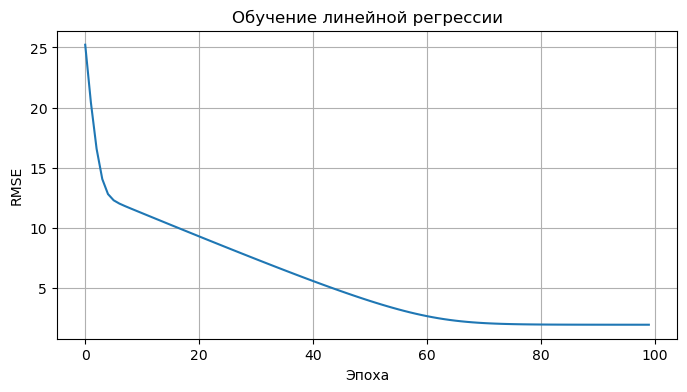

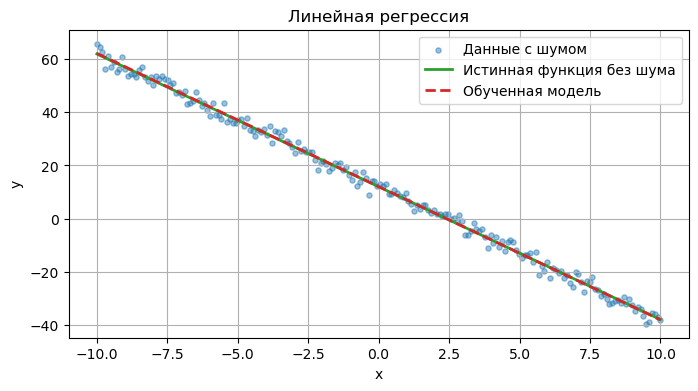

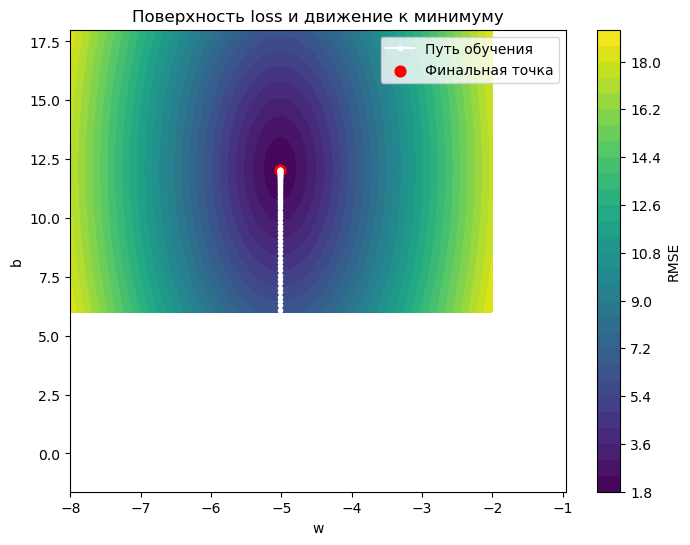

In [5]:
# Ваш код для задания 4
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Генерация данных: y = -5x + 12 + шум
x_true = torch.linspace(-10, 10, 200)
y_true = -5 * x_true + 12 + torch.randn_like(x_true) * 2.0

# Инициализация параметров
w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)

lr = 0.2
loss_history = []
w_history = []
b_history = []

for epoch in range(100):
    # Прямой проход
    y_pred = w * x_true + b
    mse = ((y_pred - y_true) ** 2).mean()
    loss = torch.sqrt(mse)
    loss_history.append(loss.item())
    w_history.append(w.item())
    b_history.append(b.item())

    # Обратный проход
    loss.backward()

    # Обновление весов
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    # Обнуление градиентов
    w.grad.zero_()
    b.grad.zero_()

print(f"Результат: w = {w.item():.3f}, b = {b.item():.3f}")

# 1. График изменения loss
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Эпоха")
plt.ylabel("RMSE")
plt.title("Обучение линейной регрессии")
plt.grid()
plt.show()

# 2. Исходная и полученная функции
with torch.no_grad():
    y_fit = w * x_true + b
    y_clean = -5 * x_true + 12

plt.figure(figsize=(8, 4))
plt.scatter(x_true, y_true, s=14, alpha=0.45, label="Данные с шумом")
plt.plot(x_true, y_clean, color="tab:green", linewidth=2, label="Истинная функция без шума")
plt.plot(x_true, y_fit, color="tab:red", linestyle="--", linewidth=2, label="Обученная модель")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Линейная регрессия")
plt.grid()
plt.legend()
plt.show()

# 3. Поверхность loss и траектория поиска минимума
w_grid = torch.linspace(-8, -2, 80)
b_grid = torch.linspace(6, 18, 80)
W, B = torch.meshgrid(w_grid, b_grid, indexing="ij")
Loss = torch.empty_like(W)

for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        pred_grid = W[i, j] * x_true + B[i, j]
        Loss[i, j] = torch.sqrt(((pred_grid - y_true) ** 2).mean())

plt.figure(figsize=(8, 6))
contours = plt.contourf(W.numpy(), B.numpy(), Loss.numpy(), levels=30, cmap="viridis")
plt.colorbar(contours, label="RMSE")
plt.plot(w_history, b_history, color="white", marker="o", markersize=3, linewidth=1.5, label="Путь обучения")
plt.scatter([w.item()], [b.item()], color="red", s=60, label="Финальная точка")
plt.xlabel("w")
plt.ylabel("b")
plt.title("Поверхность loss и движение к минимуму")
plt.legend()
plt.show()

### Выводы по заданию 4

Модель успешно обучилась вручную через `autograd`: параметр `w` сходится к значению около `-5`, а `b` — к значению около `12`, то есть к коэффициентам, которыми были сгенерированы данные.

Loss убывает по эпохам, а на контурном графике видно движение параметров в область минимума функции потерь. Основная сложность — правильно выбрать скорость обучения и обязательно обнулять градиенты после каждого шага, иначе PyTorch будет накапливать их между итерациями.

## Заключение

Поздравляю, вы пережили первое практическое занятие! Теперь вы умеете:
- создавать тензоры любой размерности;
- использовать broadcasting;
- считать градиенты вручную и доверять autograd;
- строить простые вычислительные графы.

Эти навыки пригодятся уже на следующем занятии, когда мы будем визуализировать градиентный спуск. Если остались вопросы — не стесняйтесь задавать (и да, чат с одногруппниками тоже работает).

**Сдавайте выполненную работу в виде этого блокнота с заполненными ячейками и выводами.**

Успехов!